# New York City Airbnb Market Analysis
**Recruiter-ready exploratory data analysis | Python · Pandas · Matplotlib · Seaborn**

**Business objective:** Examine Airbnb listing prices, service fees, geographic concentration, host identity verification, instant booking and cancellation policies across NYC.

**Important limitations:** The dataset contains advertised listing information, not completed reservations. `availability 365` cannot establish occupancy or actual revenue. Findings describe the supplied dataset, not necessarily the current NYC market.

**Reproducibility:** Download the original `Airbnb_Open_Data.csv` and place it in `data/` (or update `DATA_PATH`). Run all cells sequentially. This notebook deliberately contains no invented findings.

**Source:** `Airbnb_Open_Data.csv` supplied for this project. Run from the repository root. The notebook intentionally excludes invalid or missing core numeric rows from its *complete-case analytical sample*; missing booking status, verification and cancellation policy remain explicitly reported. Borough misspellings `manhatan` and `brookln` are standardised. **Caution:** Dataset provenance, time period, service-fee calculation unit, and sampling design are not independently verified.

## 0. Environment and source data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
DATA_PATH = Path("data/Airbnb_Open_Data.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Source CSV missing at {DATA_PATH.resolve()}. Add the original dataset before running.")
raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Raw dataset: {len(raw):,} rows × {raw.shape[1]} columns")
display(raw.head(3))

Raw dataset: 102,599 rows × 26 columns


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,country code,instant_bookable,cancellation_policy,room type,Construction year,price,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,US,False,strict,Private room,2020.0,$966,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,US,False,moderate,Entire home/apt,2007.0,$142,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,US,True,flexible,Private room,2005.0,$620,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN


## 1. Data quality audit and cleaning

Retain the listing `id` until checking duplicates. Missing review fields do **not** automatically invalidate listings. Record cleaning exclusions to make results auditable.

In [2]:
required = ["id", "host id", "neighbourhood group", "neighbourhood", "price", "service fee", "availability 365", "host_identity_verified", "instant_bookable", "cancellation_policy"]
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

quality_before = raw.isna().sum().sort_values(ascending=False).rename("missing_rows").to_frame()
quality_before["pct_missing"] = (100 * quality_before["missing_rows"] / len(raw)).round(2)
display(quality_before.head(20))
print("Duplicate listing IDs:", raw["id"].duplicated(keep=False).sum())
print("Repeated host IDs (expected when a host has multiple listings):", raw["host id"].duplicated(keep=False).sum())

,missing_rows,pct_missing
license,102597,100.00
house_rules,52131,50.81
last review,15893,15.49
reviews per month,15879,15.48
country,532,0.52
availability 365,448,0.44
minimum nights,409,0.40
host name,406,0.40
review rate number,326,0.32
calculated host listings count,319,0.31


Duplicate listing IDs: 1082
Repeated host IDs (expected when a host has multiple listings): 1084


In [3]:
air = raw.copy()
audit = {"input_rows": len(air)}

# Do not deduplicate by host ID: a host may legitimately manage several listings.
# Remove exact duplicate rows before resolving conflicting rows with the same listing ID.
air = air.drop_duplicates().copy()
audit["after_exact_duplicate_removal"] = len(air)
conflict_ids = air.loc[air["id"].duplicated(keep=False), "id"].nunique()
print("IDs associated with multiple nonidentical rows:", conflict_ids)
if conflict_ids:
    print("Review these conflicting listing IDs before interpreting them as unique listings:")
    display(air.loc[air["id"].duplicated(keep=False), ["id", "host id", "price", "neighbourhood group"]].head(20))
    raise ValueError("Conflicting listing IDs require manual resolution; automatic first-row selection is unsafe.")

for col in ["price", "service fee"]:
    air[col] = pd.to_numeric(air[col].astype("string").str.replace(r"[$,]", "", regex=True).str.strip(), errors="coerce")

for col in ["availability 365", "minimum nights", "number of reviews", "reviews per month"]:
    if col in air:
        air[col] = pd.to_numeric(air[col], errors="coerce")

# Normalize only categorical columns; leave listing titles and other text as-is.
air["neighbourhood group"] = (air["neighbourhood group"].astype("string").str.strip().str.title()
                              .replace({"Manhatan": "Manhattan", "Brookln": "Brooklyn"}))
air["neighbourhood"] = air["neighbourhood"].astype("string").str.strip()
air["host_identity_verified"] = air["host_identity_verified"].astype("string").str.strip().str.lower()
air["cancellation_policy"] = air["cancellation_policy"].astype("string").str.strip().str.lower()

# Preserve missing instant-booking values instead of treating them as False.
air["instant_bookable"] = (air["instant_bookable"].astype("string").str.strip().str.lower()
                           .map({"true": True, "false": False, "yes": True, "no": False, "1": True, "0": False})
                           .astype("boolean"))

if "last review" in air:
    air["last review"] = pd.to_datetime(air["last review"], errors="coerce")

# Flag invalid values; do not use abs() to conceal negative availability.
audit["invalid_availability"] = int((air["availability 365"].notna() & ~air["availability 365"].between(0,365)).sum())
audit["invalid_price"] = int((air["price"].notna() & (air["price"] <= 0)).sum())
audit["invalid_service_fee"] = int((air["service fee"].notna() & (air["service fee"] < 0)).sum())
audit["missing_availability"] = int(air["availability 365"].isna().sum())
audit["missing_price"] = int(air["price"].isna().sum())
audit["missing_service_fee"] = int(air["service fee"].isna().sum())

valid = (air["id"].notna() & air["neighbourhood group"].notna() & air["neighbourhood"].notna()
         & air["price"].gt(0) & air["service fee"].ge(0) & air["availability 365"].between(0, 365))
air = air.loc[valid].copy()
audit["after_core_validation"] = len(air)
audit["excluded_rows_total"] = audit["input_rows"] - len(air)

# Missing review dates, reviews/month, host name and house rules are NOT used for exclusion.
air["total_listed_charge"] = air["price"] + air["service fee"]  # Assumes one service fee per listed nightly price; fee unit not independently verified
# These are NOT actual revenues: availability is days open to book, not days booked.
air["hypothetical_available_night_value"] = air["price"] * air["availability 365"]

print("Cleaning audit:")
display(pd.Series(audit, name="count").to_frame())
print("Unique cleaned listing IDs:", air["id"].nunique())
print("Remaining missing values in relevant categories:")
display(air[["host_identity_verified", "instant_bookable", "cancellation_policy"]].isna().sum().rename("missing"))

IDs associated with multiple nonidentical rows: 0


Cleaning audit:


,count
input_rows,102599
after_exact_duplicate_removal,102058
invalid_availability,3185
invalid_price,0
invalid_service_fee,0
missing_availability,448
missing_price,247
missing_service_fee,273
after_core_validation,97932
excluded_rows_total,4667


Unique cleaned listing IDs: 97932
Remaining missing values in relevant categories:


host_identity_verified    257
instant_bookable           73
cancellation_policy        52
Name: missing, dtype: int64

## 2. Q1 — How do prices and service fees vary by borough and neighbourhood?

Use medians for typical prices and report sample sizes. The cost estimate assumes the fee is charged once per transaction; the dataset alone does not confirm the fee schedule.

,listings,median_price,mean_price,median_service_fee,median_listed_charge
neighbourhood group,,,,,
Bronx,2629,637.0,628.29,127.0,764.0
Queens,12817,628.0,629.52,126.0,754.0
Staten Island,923,627.0,624.28,125.0,752.0
Brooklyn,39937,626.0,626.46,125.0,751.0
Manhattan,41626,624.0,623.68,125.0,749.0


,neighbourhood group,neighbourhood,listings,median_price,median_service_fee
157,Queens,Jamaica Hills,21,971.0,194.0
11,Bronx,East Morrisania,20,881.0,176.0
212,Staten Island,Shore Acres,20,871.0,174.0
48,Brooklyn,Bath Beach,46,826.5,165.5
22,Bronx,Morris Park,45,798.0,160.0
78,Brooklyn,Gravesend,136,797.0,159.5
159,Queens,Kew Gardens Hills,66,794.0,159.0
137,Queens,Cambria Heights,73,787.0,157.0
29,Bronx,Olinville,22,768.5,153.5
63,Brooklyn,Columbia St,86,765.5,153.0


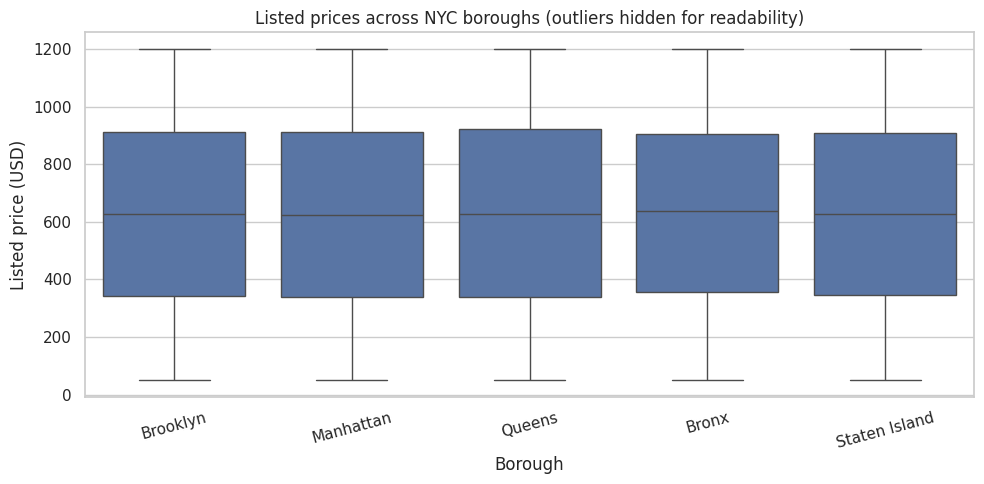

In [4]:
borough_pricing = (air.groupby("neighbourhood group").agg(
    listings=("id", "nunique"), median_price=("price", "median"), mean_price=("price", "mean"),
    median_service_fee=("service fee", "median"), median_listed_charge=("total_listed_charge", "median")
).round(2).sort_values("median_price", ascending=False))
display(borough_pricing)

neighbourhood_pricing = (air.groupby(["neighbourhood group", "neighbourhood"]).agg(
    listings=("id", "nunique"), median_price=("price", "median"),
    median_service_fee=("service fee", "median")
).reset_index())
# Minimum sample size avoids spotlighting neighbourhood medians based on one listing.
display(neighbourhood_pricing.query("listings >= 20").sort_values("median_price", ascending=False).head(15))

fig, ax = plt.subplots(figsize=(10,5))
sns.boxplot(data=air, x="neighbourhood group", y="price", showfliers=False, ax=ax)
ax.set(title="Listed prices across NYC boroughs (outliers hidden for readability)", xlabel="Borough", ylabel="Listed price (USD)")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 3. Q2 — Which boroughs have the highest listing concentration?

,borough,listings,share_pct
0,Manhattan,41626,42.51
1,Brooklyn,39937,40.78
2,Queens,12817,13.09
3,Bronx,2629,2.68
4,Staten Island,923,0.94


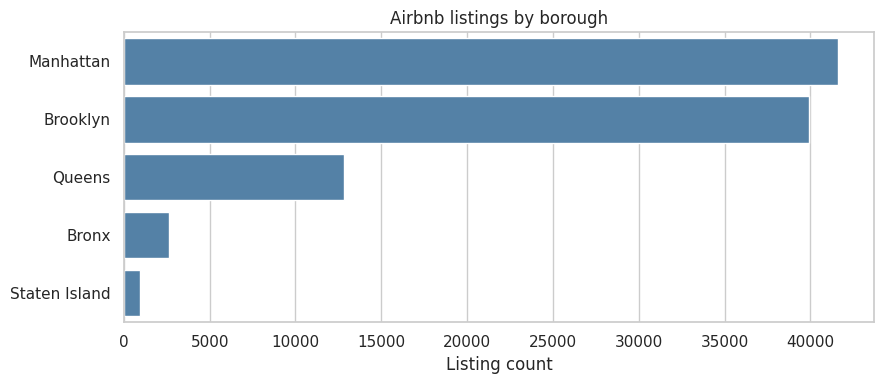

In [5]:
borough_count = air["neighbourhood group"].value_counts(dropna=False).rename_axis("borough").reset_index(name="listings")
borough_count["share_pct"] = (borough_count["listings"] / len(air) * 100).round(2)
display(borough_count)
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(data=borough_count,x="listings",y="borough",color="steelblue",ax=ax)
ax.set(title="Airbnb listings by borough",xlabel="Listing count",ylabel="");plt.tight_layout();plt.show()

## 4. Q3 — What share of listings belongs to verified versus unconfirmed hosts?

This is the **share of listings by verification label**, not the proportion of distinct hosts. Hosts may own multiple listings. Unknown labels are retained.

,verification_status,listings,share_pct
0,unconfirmed,48882,49.91
1,verified,48793,49.82
2,unknown,257,0.26


Hosts with inconsistent verification labels: 0


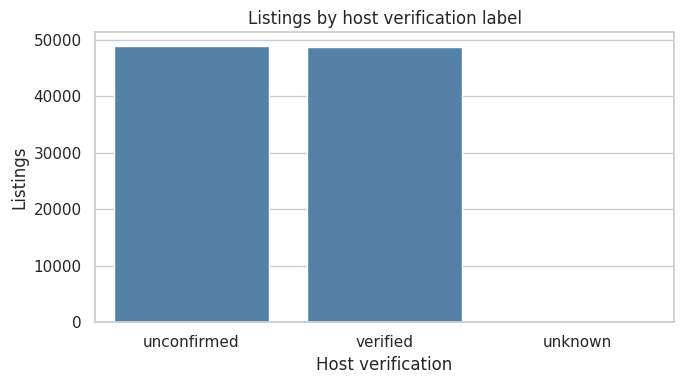

In [6]:
verification = air["host_identity_verified"].fillna("unknown").value_counts(dropna=False).rename_axis("verification_status").reset_index(name="listings")
verification["share_pct"] = (verification["listings"] / len(air) * 100).round(2)
display(verification)
# Distinct-host shares are a separate question; flag hosts with inconsistent labels.
hosts = air.loc[air["host id"].notna(), ["host id", "host_identity_verified"]].drop_duplicates()
inconsistent_hosts = hosts.groupby("host id")["host_identity_verified"].nunique(dropna=False).gt(1).sum()
print("Hosts with inconsistent verification labels:", inconsistent_hosts)
fig,ax=plt.subplots(figsize=(7,4))
sns.barplot(data=verification,x="verification_status",y="listings",color="steelblue",ax=ax)
ax.set(title="Listings by host verification label",xlabel="Host verification",ylabel="Listings");plt.tight_layout();plt.show()

## 5. Q4 — How does instant-booking availability differ across locations?

Percentages below use only listings with a known booking status; unknown counts are reported separately.

,eligible_listings,instant_bookable_pct,unknown_booking_status
neighbourhood group,,,
Staten Island,922,51.84,1
Bronx,2628,50.3,1
Brooklyn,39898,49.77,39
Manhattan,41598,49.73,28
Queens,12813,49.36,4


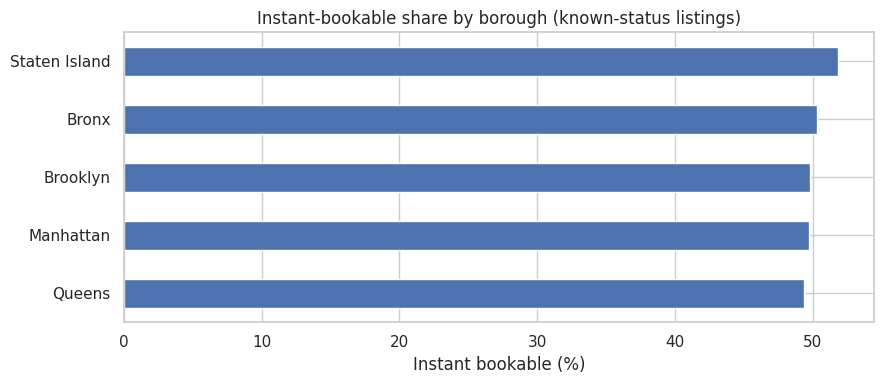

In [7]:
booked = air.dropna(subset=["instant_bookable"]).copy()
instant_by_borough = (booked.groupby("neighbourhood group").agg(
    eligible_listings=("id", "nunique"), instant_bookable_pct=("instant_bookable", "mean")
).assign(instant_bookable_pct=lambda x: (100*x["instant_bookable_pct"]).round(2)))
missing_booking = air.groupby("neighbourhood group")["instant_bookable"].apply(lambda x: x.isna().sum()).rename("unknown_booking_status")
display(instant_by_borough.join(missing_booking).sort_values("instant_bookable_pct",ascending=False))
fig,ax=plt.subplots(figsize=(9,4))
instant_by_borough["instant_bookable_pct"].sort_values().plot.barh(ax=ax)
ax.set(title="Instant-bookable share by borough (known-status listings)",xlabel="Instant bookable (%)",ylabel="");plt.tight_layout();plt.show()

## 6. Q5 — How do cancellation policies vary?

,policy,listings,share_pct
0,moderate,32740,33.43
1,strict,32588,33.28
2,flexible,32552,33.24
3,unknown,52,0.05


cancellation_policy,flexible,moderate,strict,unknown
neighbourhood group,,,,
Bronx,33.78,33.21,32.98,0.04
Brooklyn,32.98,33.45,33.49,0.07
Manhattan,33.62,33.37,32.97,0.04
Queens,32.78,33.47,33.71,0.03
Staten Island,31.85,35.54,32.50,0.11


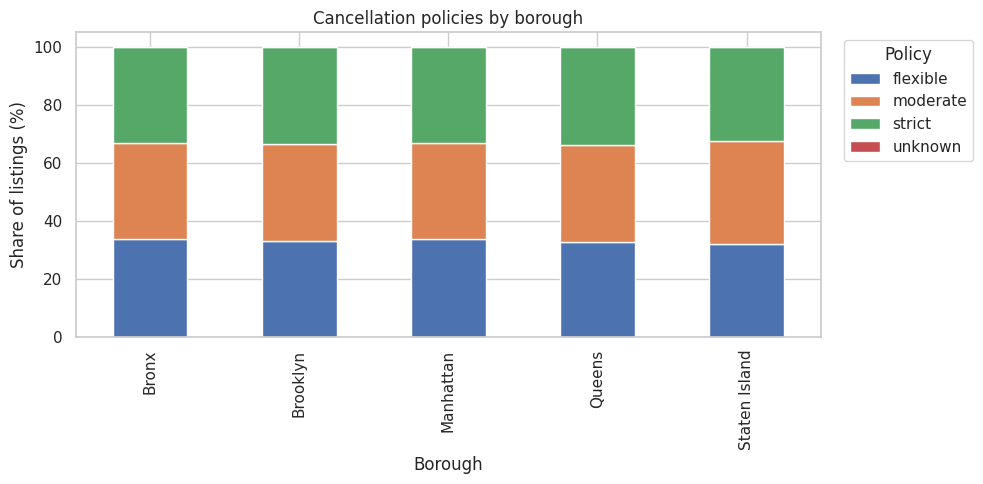

In [8]:
policy = air["cancellation_policy"].fillna("unknown").value_counts(dropna=False).rename_axis("policy").reset_index(name="listings")
policy["share_pct"] = (100*policy["listings"]/len(air)).round(2)
display(policy)
policy_by_borough = pd.crosstab(air["neighbourhood group"],air["cancellation_policy"].fillna("unknown"),normalize="index").mul(100).round(2)
display(policy_by_borough)
ax=policy_by_borough.plot(kind="bar",stacked=True,figsize=(10,5))
ax.set(title="Cancellation policies by borough",xlabel="Borough",ylabel="Share of listings (%)")
ax.legend(title="Policy",bbox_to_anchor=(1.02,1),loc="upper left");plt.tight_layout();plt.show()

## 7. Q6 — What can hosts and marketplace operators learn?

Compare market segments on typical listed prices, availability and instant-booking adoption. **Availability represents days offered for booking, not occupied nights.** This is descriptive segmentation, not proof of demand, performance or causality.

,listings,median_price,median_availability_days,avg_availability_days,instant_booking_known,instant_booking_share
neighbourhood group,,,,,,
Bronx,2629,637.0,168.0,177.24,2628,50.0
Queens,12817,628.0,137.0,158.66,12813,49.0
Staten Island,923,627.0,187.0,196.00,922,52.0
Brooklyn,39937,626.0,79.0,122.65,39898,50.0
Manhattan,41626,624.0,93.0,134.43,41598,50.0


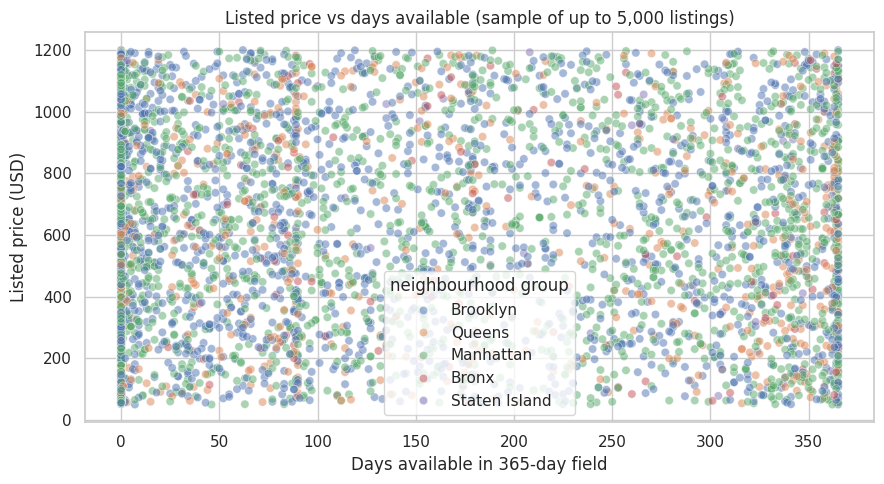

Interpretation guide:
• Higher listing share indicates concentration in this dataset, NOT necessarily greater demand.
• Higher listed price does not imply higher completed transaction revenue.
• Greater availability may signal more open dates; it does NOT directly measure occupancy.
• Compare room types, location and amenities before making pricing recommendations.


In [9]:
market = air.groupby("neighbourhood group").agg(
    listings=("id", "nunique"), median_price=("price", "median"),
    median_availability_days=("availability 365", "median"),
    avg_availability_days=("availability 365", "mean"),
    instant_booking_known=("instant_bookable", "count"),
    instant_booking_share=("instant_bookable", "mean")
).round(2)
market["instant_booking_share"] = (100*market["instant_booking_share"]).round(2)
display(market.sort_values("median_price",ascending=False))

fig,ax=plt.subplots(figsize=(9,5))
sns.scatterplot(data=air.sample(min(5000,len(air)),random_state=42),x="availability 365",y="price",hue="neighbourhood group",alpha=.5,ax=ax)
ax.set(title="Listed price vs days available (sample of up to 5,000 listings)",xlabel="Days available in 365-day field",ylabel="Listed price (USD)")
plt.tight_layout();plt.show()

print("Interpretation guide:")
print("• Higher listing share indicates concentration in this dataset, NOT necessarily greater demand.")
print("• Higher listed price does not imply higher completed transaction revenue.")
print("• Greater availability may signal more open dates; it does NOT directly measure occupancy.")
print("• Compare room types, location and amenities before making pricing recommendations.")

## 8. Export reproducible tables and a cleaned dataset

The cleaned CSV preserves numerical price/fee columns and omits the DataFrame index. Do not publish raw or derived files if dataset redistribution is restricted.

In [10]:
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
air.to_csv(OUT / "airbnb_cleaned.csv", index=False)
borough_pricing.to_csv(OUT / "borough_pricing.csv")
borough_count.to_csv(OUT / "borough_listing_share.csv", index=False)
verification.to_csv(OUT / "host_verification_listing_share.csv", index=False)
instant_by_borough.join(missing_booking).to_csv(OUT / "instant_booking_by_borough.csv")
policy_by_borough.to_csv(OUT / "cancellation_policy_by_borough.csv")
market.to_csv(OUT / "market_summary.csv")
print(f"Exported 7 files to {OUT.resolve()}")

Exported 7 files to /mnt/data/airbnb_portfolio/outputs


## 9. Evidence-based executive summary

See `README.md` for the measured results and limitations. This notebook computes and displays the exact tables supporting all six analytical questions. The CSV is a snapshot of **listings**, not historical reservations. Availability is not occupancy, and no revenue estimates are presented as observed earnings. The year, sampling method and representativeness of the dataset have not been independently verified.